# Plugging the Gap: Data-Driven EV Charging Expansion in India

**Machine Learning Algorithm - II | MBA (Business Analytics), Trimester IV | Group 9**

Unsupervised segmentation of Indian states by EV-ecosystem profile, to rank
charging-infrastructure expansion priorities for a network operator.

**Inputs** (place these three CSVs in the same folder as this notebook):

| File | Source | Granularity |
|---|---|---|
| `EV_Sales_by_State_2014-2024.csv` | Vahan Dashboard, MoRTH (compiled) | state x month x vehicle class |
| `OperationalPC.csv` | Ministry of Power, as on 02.02.2024 (PIB PRID 2003003) | state |
| `India_State_Population_Census2011.csv` | Census of India 2011 | state |

**Pipeline:** harmonise -> merge -> engineer -> scale -> PCA -> K-Means -> validate -> profile -> score -> rank.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import dendrogram, linkage

RANDOM_STATE = 42
DATA_DIR = ""                 # "" = same folder as this notebook

pd.set_option("display.width", 200, "display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 5),
                     "axes.titleweight": "bold"})
print("Environment ready.")

Environment ready.


## 1. Data Loading

First look at all three sources before any transformation.

In [2]:
sales = pd.read_csv(DATA_DIR + "EV_Sales_by_State_2014-2024.csv")
pcs   = pd.read_csv(DATA_DIR + "OperationalPC.csv", encoding="utf-8-sig")
pop   = pd.read_csv(DATA_DIR + "India_State_Population_Census2011.csv")

for name, d in [("sales", sales), ("pcs", pcs), ("pop", pop)]:
    print(f"{name:6s} shape={str(d.shape):12s} nulls={int(d.isna().sum().sum()):3d}  "
          f"cols={list(d.columns)}")

sales.head(3)

sales  shape=(96845, 8)   nulls=  0  cols=['Year', 'Month_Name', 'Date', 'State', 'Vehicle_Class', 'Vehicle_Category', 'Vehicle_Type', 'EV_Sales_Quantity']
pcs    shape=(34, 2)      nulls=  0  cols=['State', 'No. of Operational PCS']
pop    shape=(35, 5)      nulls=  0  cols=['State_Census', 'Population', 'Male', 'Female', 'Literate']


,Year,Month_Name,Date,State,Vehicle_Class,Vehicle_Category,Vehicle_Type,EV_Sales_Quantity
0,2014.0,jan,1/1/2014,Andhra Pradesh,ADAPTED VEHICLE,Others,Others,0.0
1,2014.0,jan,1/1/2014,Andhra Pradesh,AGRICULTURAL TRACTOR,Others,Others,0.0
2,2014.0,jan,1/1/2014,Andhra Pradesh,AMBULANCE,Others,Others,0.0


In [3]:
# Sanity check: does the charging file match the official national total?
print("Total operational public charging stations:", pcs["No. of Operational PCS"].sum())
print("Ministry of Power figure, 02.02.2024      : 12146")
pcs.sort_values("No. of Operational PCS", ascending=False).head(8)

Total operational public charging stations: 12146
Ministry of Power figure, 02.02.2024      : 12146


,State,No. of Operational PCS
19,Maharashtra,3079
8,Delhi,1886
15,Karnataka,1041
16,Kerala,852
28,Tamil Nadu,643
31,Uttar Pradesh,582
26,Rajasthan,500
29,Telangana,481


## 2. State Name Harmonisation

**Challenge 1 - the merge key does not exist.** The same state is spelled
differently in all three sources, and the three files use *different geographic
vintages*. Naive merging silently drops rows.

Decisions taken, and why:

| Issue | Decision | Rationale |
|---|---|---|
| Telangana in charging data, absent from Vahan sales | fold into Andhra Pradesh | Census 2011 predates the 2014 bifurcation, so its AP figure already includes Telangana. Folding gives one consistent boundary definition across all three files. |
| Ladakh separate in sales, absent elsewhere | fold into Jammu & Kashmir | same vintage argument (2019 reorganisation) |
| `DNH and DD` / `D&D and DNH` / two Census rows | single `DNH & DD` | 2020 UT merger |
| `Pondicherry` / `Puducherry`, `Orissa` / `Odisha`, `Nct Of Delhi` / `Delhi` | canonical modern name | pure spelling |

In [4]:
sales_map = {"Andaman & Nicobar Island": "Andaman & Nicobar",
             "DNH and DD": "DNH & DD",
             "Jammu and Kashmir": "Jammu & Kashmir",
             "Ladakh": "Jammu & Kashmir"}

pcs_map   = {"D&D and DNH": "DNH & DD",
             "Pondicherry": "Puducherry",
             "Jammu and Kashmir": "Jammu & Kashmir",
             "Telangana": "Andhra Pradesh"}

pop_map   = {"Andaman And Nicobar Islands": "Andaman & Nicobar",
             "Dadra And Nagar Haveli": "DNH & DD",
             "Daman And Diu": "DNH & DD",
             "Jammu And Kashmir": "Jammu & Kashmir",
             "Nct Of Delhi": "Delhi",
             "Orissa": "Odisha",
             "Pondicherry": "Puducherry"}

sales["St"] = sales["State"].str.strip().replace(sales_map)
pcs["St"]   = pcs["State"].str.strip().replace(pcs_map)
pop["St"]   = pop["State_Census"].str.strip().replace(pop_map)

S, P, C = set(sales.St), set(pcs.St), set(pop.St)
print(f"Distinct states after mapping -> sales {len(S)} | charging {len(P)} | population {len(C)}\n")
print("Sales data but NO charging data :", sorted(S - P))
print("Charging data but NO sales data :", sorted(P - S))
print("Missing population              :", sorted((S | P) - C))

Distinct states after mapping -> sales 33 | charging 33 | population 34

Sales data but NO charging data : ['Mizoram']
Charging data but NO sales data : ['Lakshadweep']
Missing population              : []


## 3. Temporal Coverage Check

**Challenge 2 - the latest year is not a year.** 2024 contains January only.
Treating it as a full year would understate every state's most recent volume by
roughly 90% and corrupt every growth feature. **2023 is the latest complete year.**

,months,total_ev_sales
Year,,
2014.0,12,2392.0
2015.0,12,7805.0
2016.0,12,49855.0
2017.0,12,87420.0
2018.0,12,130254.0
2019.0,12,166819.0
2020.0,12,124684.0
2021.0,12,331498.0
2022.0,12,1024723.0



Using 2023 as latest complete year; growth measured from 2019.


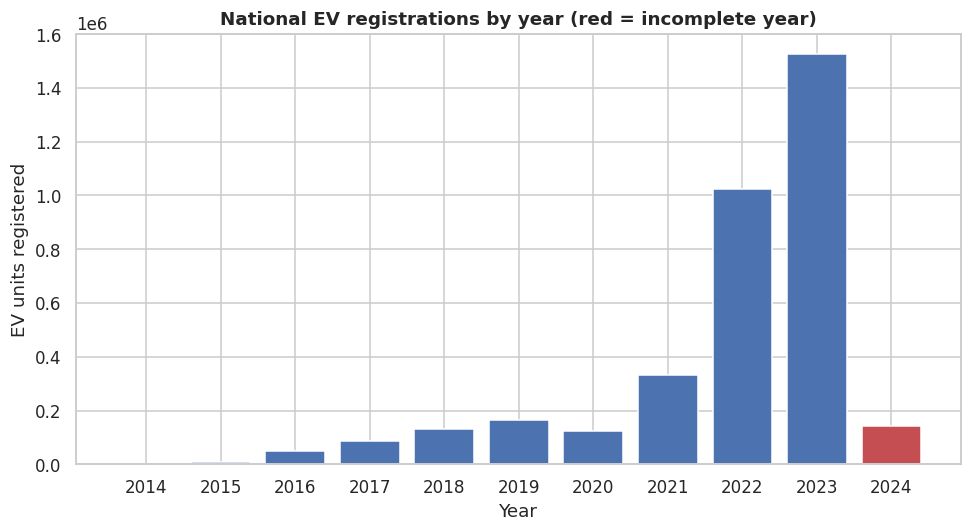

In [5]:
coverage = (sales.groupby("Year")
                 .agg(months=("Month_Name", "nunique"),
                      total_ev_sales=("EV_Sales_Quantity", "sum")))
display(coverage)

LATEST, BASE_YR = 2023, 2019
print(f"\nUsing {LATEST} as latest complete year; growth measured from {BASE_YR}.")

fig, ax = plt.subplots()
ax.bar(coverage.index.astype(int).astype(str), coverage.total_ev_sales,
       color=np.where(coverage.months == 12, "#4C72B0", "#C44E52"))
ax.set(title="National EV registrations by year (red = incomplete year)",
       ylabel="EV units registered", xlabel="Year")
plt.tight_layout(); plt.show()

## 4. Aggregation and Merge

Each source is collapsed to one row per state, then inner-joined.

In [6]:
s_latest = sales[sales.Year == LATEST]

# --- demand
demand = s_latest.groupby("St").EV_Sales_Quantity.sum().rename("ev_sales_2023")

# --- vehicle-category mix (share of latest-year sales)
mix = (s_latest.pivot_table(index="St", columns="Vehicle_Category",
                            values="EV_Sales_Quantity", aggfunc="sum").fillna(0))
mix_share = mix.div(mix.sum(axis=1).replace(0, np.nan), axis=0)
mix_share.columns = ["share_" + str(x).lower().replace("-", "").replace(" ", "")
                     for x in mix_share.columns]

# --- growth
base = sales[sales.Year == BASE_YR].groupby("St").EV_Sales_Quantity.sum()
cagr = ((demand / base.replace(0, np.nan)) ** (1 / (LATEST - BASE_YR)) - 1).rename("cagr_19_23")

# --- supply and population
supply = pcs.groupby("St")["No. of Operational PCS"].sum().rename("pcs")
popn   = pop.groupby("St").Population.sum().rename("population")

df = (pd.concat([demand, cagr, mix_share], axis=1)
        .join(supply, how="inner").join(popn, how="inner"))

zero = sorted(df[df.ev_sales_2023 == 0].index)
df = df[df.ev_sales_2023 > 0]

print("Dropped - no charging data :", sorted(S - P))
print("Dropped - no sales data    :", sorted(P - S))
print("Dropped - zero 2023 sales  :", zero, "(growth and gap ratios undefined)")
print(f"\nAnalytical base table: {df.shape[0]} states")

Dropped - no charging data : ['Mizoram']
Dropped - no sales data    : ['Lakshadweep']
Dropped - zero 2023 sales  : ['Sikkim'] (growth and gap ratios undefined)

Analytical base table: 31 states


## 5. Feature Engineering

**Design rule: every feature is size-normalised.** Raw counts would make the
clustering rediscover state population - Uttar Pradesh and Maharashtra in one
group, Sikkim and Nagaland in another - which is not an insight. Market size is
retained as exactly one log-transformed dimension so scale enters the model once,
in tamed form, rather than through every variable.

| Feature | Block | Business meaning |
|---|---|---|
| `ev_per_lakh` | demand | EV adoption intensity |
| `log_market_size` | demand | absolute opportunity, compressed |
| `cagr_19_23` | maturity | momentum |
| `share_2wheelers` / `_3wheelers` / `_4wheelers` | demand | what kind of charging is needed |
| `pcs_per_lakh` | infrastructure | how well served the population is |
| `evs_per_station` | **gap** | demand pressure per charge point - the core metric |

In [7]:
df["pop_lakh"]        = df.population / 1e5
df["ev_per_lakh"]     = df.ev_sales_2023 / df.pop_lakh
df["pcs_per_lakh"]    = df.pcs / df.pop_lakh
df["evs_per_station"] = df.ev_sales_2023 / df.pcs.replace(0, np.nan)
df["log_market_size"] = np.log1p(df.ev_sales_2023)

FEATURES = ["ev_per_lakh", "pcs_per_lakh", "evs_per_station", "log_market_size",
            "cagr_19_23", "share_2wheelers", "share_3wheelers", "share_4wheelers"]

print("Nulls in feature matrix:", int(df[FEATURES].isna().sum().sum()))
df[FEATURES].describe().T.round(2)

Nulls in feature matrix: 0


,count,mean,std,min,25%,50%,75%,max
ev_per_lakh,31.0,146.35,157.88,0.30,32.25,120.27,172.19,647.22
pcs_per_lakh,31.0,1.38,2.30,0.12,0.44,0.65,1.05,11.23
evs_per_station,31.0,182.45,189.87,1.00,50.99,145.31,214.19,711.18
log_market_size,31.0,9.14,2.89,1.95,8.31,10.16,11.21,12.53
cagr_19_23,31.0,1.01,0.72,-0.33,0.55,0.92,1.27,2.90
share_2wheelers,31.0,0.53,0.29,0.04,0.29,0.53,0.84,0.93
share_3wheelers,31.0,0.34,0.33,0.00,0.04,0.30,0.63,0.95
share_4wheelers,31.0,0.13,0.19,0.00,0.03,0.07,0.12,0.86


## 6. Exploratory Analysis

The business thesis should be visible before any model is fitted.

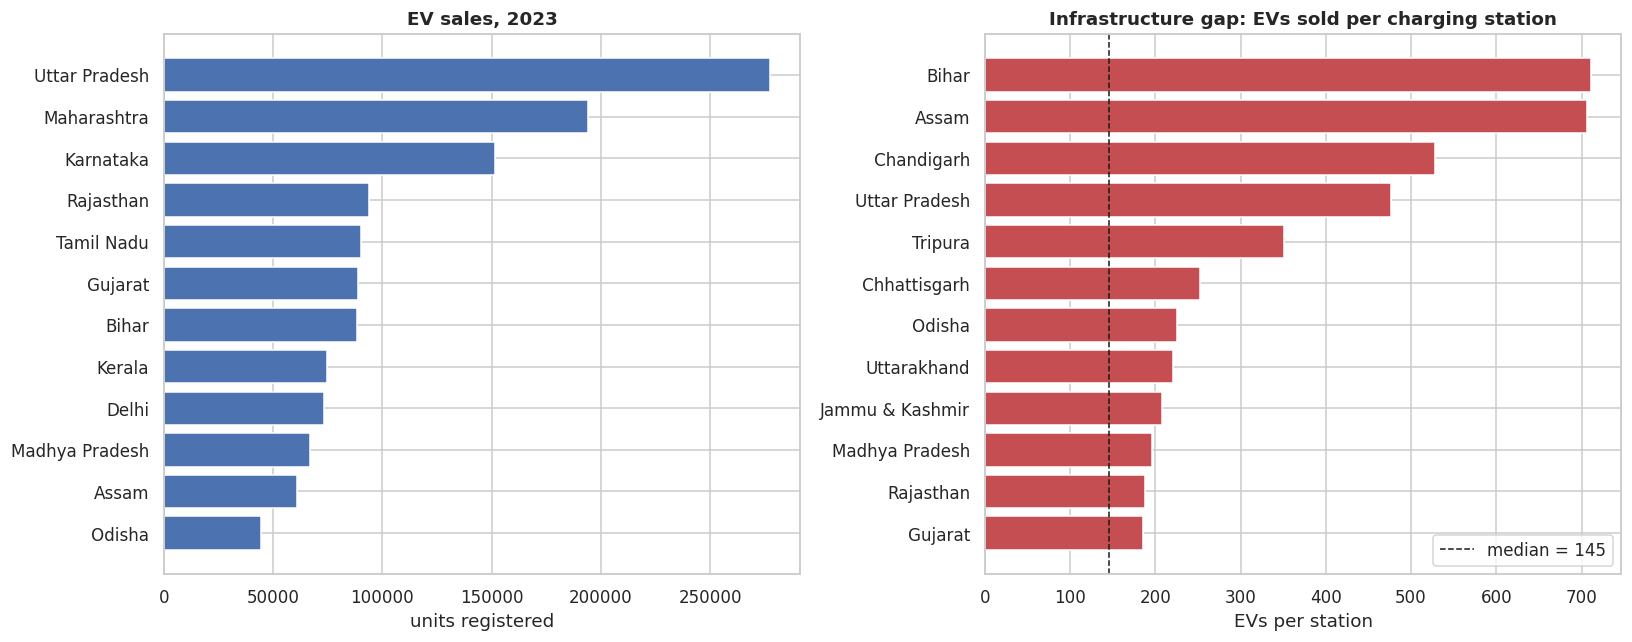

Most under-served: Bihar (711 EVs per station)
Best served      : Nagaland (1 EVs per station)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top = df.nlargest(12, "ev_sales_2023")
axes[0].barh(top.index[::-1], top.ev_sales_2023[::-1], color="#4C72B0")
axes[0].set(title=f"EV sales, {LATEST}", xlabel="units registered")

gap = df.nlargest(12, "evs_per_station")
axes[1].barh(gap.index[::-1], gap.evs_per_station[::-1], color="#C44E52")
axes[1].axvline(df.evs_per_station.median(), ls="--", c="k", lw=1,
                label=f"median = {df.evs_per_station.median():.0f}")
axes[1].set(title="Infrastructure gap: EVs sold per charging station", xlabel="EVs per station")
axes[1].legend()
plt.tight_layout(); plt.show()

print("Most under-served:", df.evs_per_station.idxmax(),
      f"({df.evs_per_station.max():.0f} EVs per station)")
print("Best served      :", df.evs_per_station.idxmin(),
      f"({df.evs_per_station.min():.0f} EVs per station)")

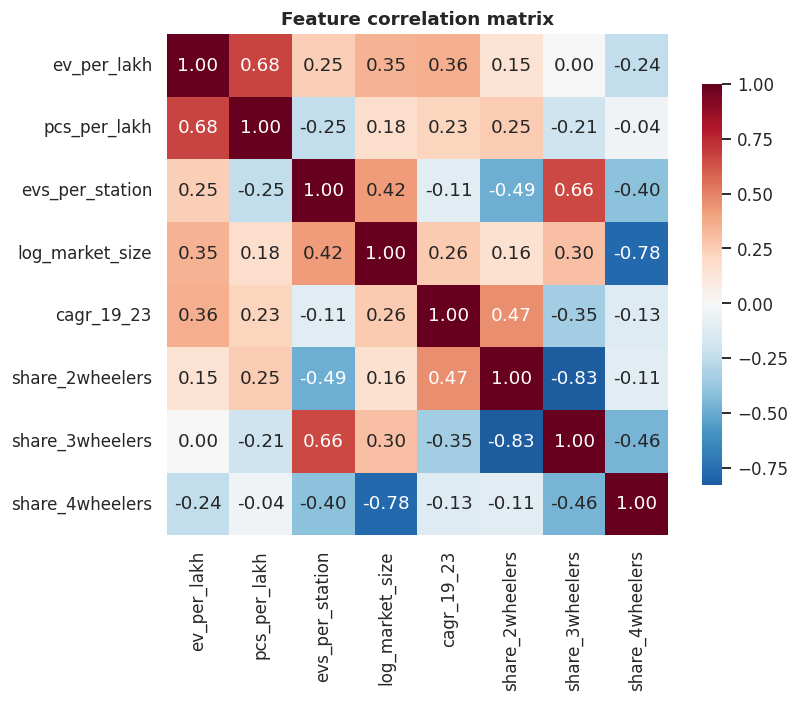

In [9]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, square=True, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Feature correlation matrix")
plt.tight_layout(); plt.show()

## 7. Standardisation and PCA

**Challenge 3 - n = 31.** With 31 observations and 8 features, K-Means on the raw
feature space is unstable: distances are dominated by whichever variables happen
to be extreme, and cluster assignments shift when a single state is removed.

PCA is therefore not decoration here. Clustering on the leading principal
components denoises the space, removes the correlation between `ev_per_lakh`
and `log_market_size`, and keeps the observations-to-dimensions ratio defensible.

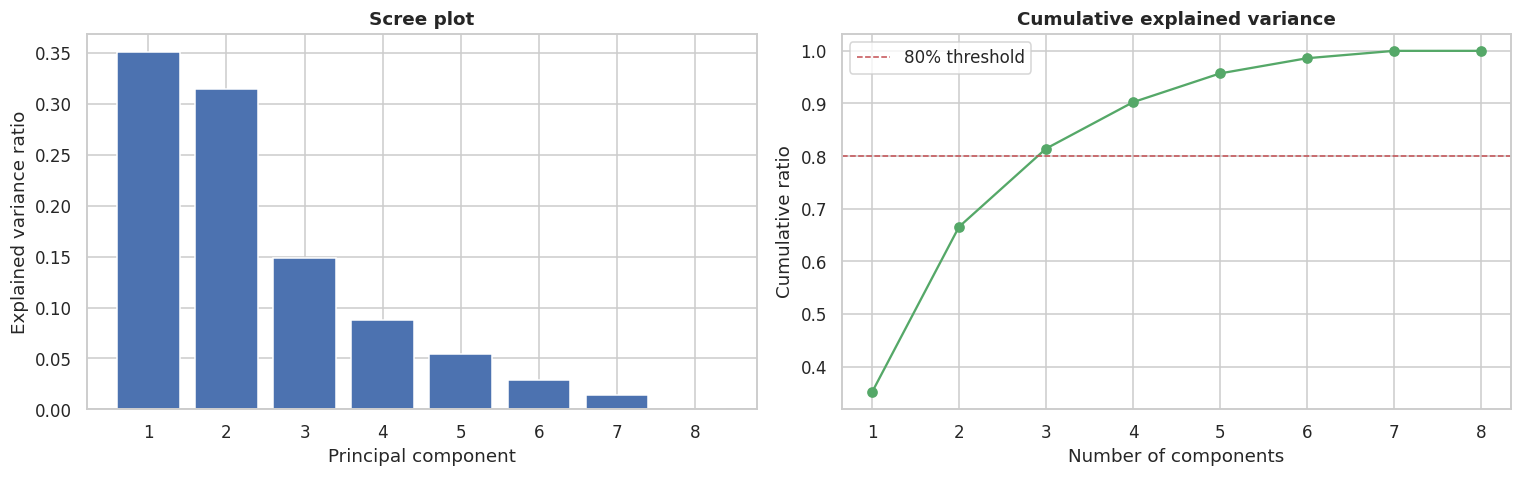

Components retained: 3  (cumulative variance 81.4%)


In [10]:
X = StandardScaler().fit_transform(df[FEATURES])

pca_full = PCA(random_state=RANDOM_STATE).fit(X)
evr = pca_full.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(range(1, len(evr) + 1), evr, color="#4C72B0")
axes[0].set(title="Scree plot", xlabel="Principal component", ylabel="Explained variance ratio")
axes[1].plot(range(1, len(evr) + 1), evr.cumsum(), "o-", color="#55A868")
axes[1].axhline(.80, ls="--", c="r", lw=1, label="80% threshold")
axes[1].set(title="Cumulative explained variance", xlabel="Number of components", ylabel="Cumulative ratio")
axes[1].legend()
plt.tight_layout(); plt.show()

N_PC = int((evr.cumsum() < .80).sum() + 1)
print(f"Components retained: {N_PC}  (cumulative variance {evr.cumsum()[N_PC-1]:.1%})")

In [11]:
pca = PCA(n_components=N_PC, random_state=RANDOM_STATE)
Xp = pca.fit_transform(X)

loadings = pd.DataFrame(pca.components_.T,
                        index=FEATURES,
                        columns=[f"PC{i+1}" for i in range(N_PC)])
display(loadings.round(3).style.background_gradient(cmap="RdBu_r", axis=None)
        .set_caption("PCA loadings - how to name each latent factor"))

for i in range(N_PC):
    top = loadings[f"PC{i+1}"].abs().nlargest(3).index.tolist()
    print(f"PC{i+1} ({evr[i]:.1%} of variance) driven by: {', '.join(top)}")

,PC1,PC2,PC3
ev_per_lakh,0.028000,0.477000,0.508000
pcs_per_lakh,-0.170000,0.383000,0.582000
evs_per_station,0.497000,0.086000,0.029000
log_market_size,0.277000,0.463000,-0.287000
cagr_19_23,-0.200000,0.389000,-0.176000
share_2wheelers,-0.421000,0.316000,-0.377000
share_3wheelers,0.564000,-0.066000,0.134000
share_4wheelers,-0.333000,-0.386000,0.358000


PC1 (35.1% of variance) driven by: share_3wheelers, evs_per_station, share_2wheelers
PC2 (31.4% of variance) driven by: ev_per_lakh, log_market_size, cagr_19_23
PC3 (14.9% of variance) driven by: pcs_per_lakh, ev_per_lakh, share_2wheelers


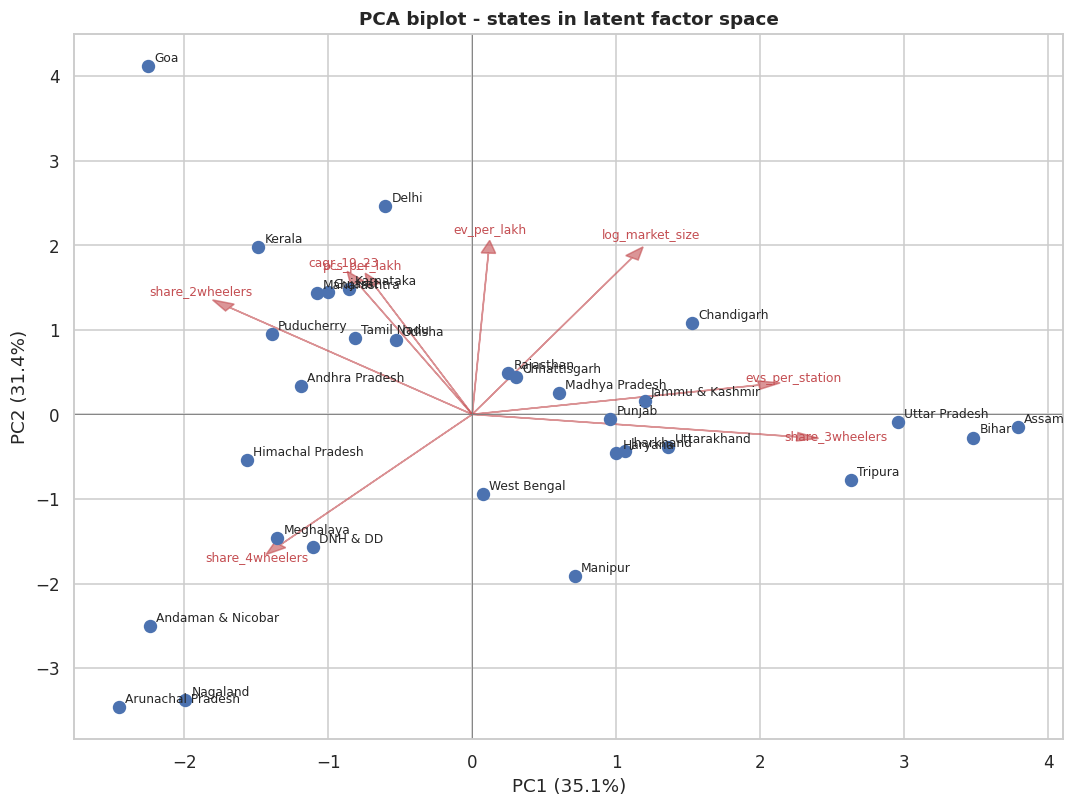

In [12]:
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.scatter(Xp[:, 0], Xp[:, 1], s=60, c="#4C72B0", zorder=3)
for i, st in enumerate(df.index):
    ax.annotate(st, (Xp[i, 0], Xp[i, 1]), fontsize=8,
                xytext=(4, 3), textcoords="offset points")
for f in FEATURES:
    vx, vy = loadings.loc[f, "PC1"] * 4, loadings.loc[f, "PC2"] * 4
    ax.arrow(0, 0, vx, vy, color="#C44E52", alpha=.6, head_width=.1, zorder=2)
    ax.text(vx * 1.12, vy * 1.12, f, color="#C44E52", fontsize=8, ha="center")
ax.axhline(0, c="grey", lw=.6); ax.axvline(0, c="grey", lw=.6)
ax.set(title="PCA biplot - states in latent factor space",
       xlabel=f"PC1 ({evr[0]:.1%})", ylabel=f"PC2 ({evr[1]:.1%})")
plt.tight_layout(); plt.show()

## 8. Choosing k

Four criteria, reported together. Silhouette and Calinski-Harabasz should be
**maximised**; Davies-Bouldin should be **minimised**. Agreement across all three
is stronger evidence than any single index.

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,138.590000,0.294000,1.189000,13.250000
3,82.977000,0.403000,0.854000,20.067000
4,49.281000,0.441000,0.680000,27.875000
5,33.403000,0.463000,0.675000,32.791000
6,25.232000,0.474000,0.628000,35.011000
7,19.278000,0.482000,0.521000,37.896000
8,15.725000,0.466000,0.432000,38.903000


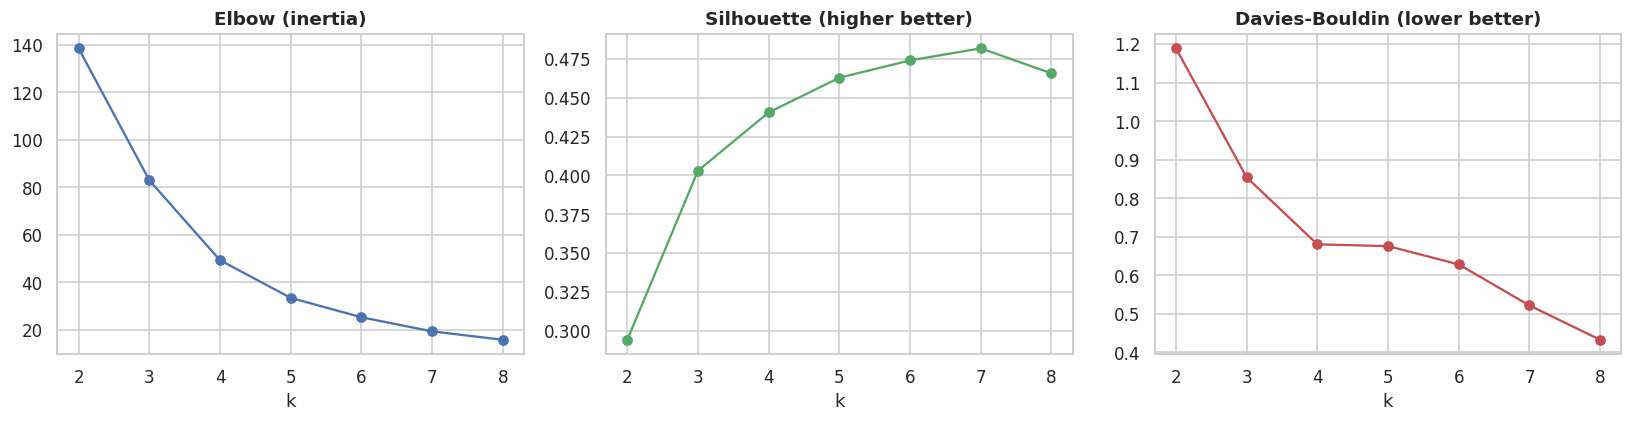

In [13]:
rows = []
for k in range(2, 9):
    lab = KMeans(n_clusters=k, n_init=25, random_state=RANDOM_STATE).fit_predict(Xp)
    rows.append({"k": k,
                 "inertia": KMeans(n_clusters=k, n_init=25, random_state=RANDOM_STATE).fit(Xp).inertia_,
                 "silhouette": silhouette_score(Xp, lab),
                 "davies_bouldin": davies_bouldin_score(Xp, lab),
                 "calinski_harabasz": calinski_harabasz_score(Xp, lab)})
diag = pd.DataFrame(rows).set_index("k")
display(diag.round(3).style.highlight_max(subset=["silhouette", "calinski_harabasz"], color="#c6efce")
        .highlight_min(subset=["davies_bouldin"], color="#c6efce"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(diag.index, diag.inertia, "o-"); axes[0].set(title="Elbow (inertia)", xlabel="k")
axes[1].plot(diag.index, diag.silhouette, "o-", color="#55A868"); axes[1].set(title="Silhouette (higher better)", xlabel="k")
axes[2].plot(diag.index, diag.davies_bouldin, "o-", color="#C44E52"); axes[2].set(title="Davies-Bouldin (lower better)", xlabel="k")
plt.tight_layout(); plt.show()

In [14]:
# Business constraint: the proposal commits to a 4-tier investment matrix.
# Verify that k=4 is statistically defensible before adopting it.
K = 4
print(f"Statistically optimal k by silhouette : {diag.silhouette.idxmax()}")
print(f"k adopted for the segmentation        : {K}")
print(f"Silhouette at k={K}: {diag.loc[K,'silhouette']:.3f}   "
      f"(best available: {diag.silhouette.max():.3f})")

Statistically optimal k by silhouette : 7
k adopted for the segmentation        : 4
Silhouette at k=4: 0.441   (best available: 0.482)


## 9. K-Means Segmentation

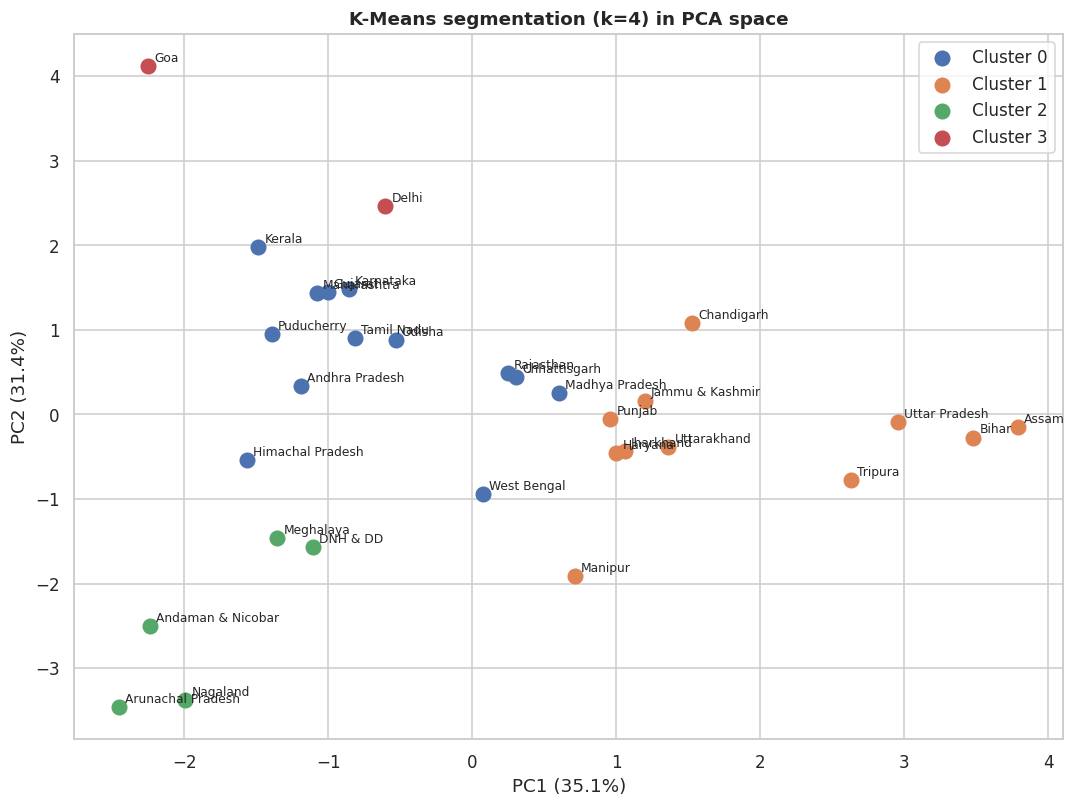

Cluster 0 (n=13): Andhra Pradesh, Chhattisgarh, Gujarat, Himachal Pradesh, Karnataka, Kerala, Madhya Pradesh, Maharashtra, Odisha, Puducherry, Rajasthan, Tamil Nadu, West Bengal
Cluster 1 (n=11): Assam, Bihar, Chandigarh, Haryana, Jammu & Kashmir, Jharkhand, Manipur, Punjab, Tripura, Uttar Pradesh, Uttarakhand
Cluster 2 (n= 5): Andaman & Nicobar, Arunachal Pradesh, DNH & DD, Meghalaya, Nagaland
Cluster 3 (n= 2): Delhi, Goa


In [15]:
km = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE)
df["cluster"] = km.fit_predict(Xp)

fig, ax = plt.subplots(figsize=(10, 7.5))
for cl in sorted(df.cluster.unique()):
    m = df.cluster == cl
    ax.scatter(Xp[m.values, 0], Xp[m.values, 1], s=90, label=f"Cluster {cl}", zorder=3)
for i, st in enumerate(df.index):
    ax.annotate(st, (Xp[i, 0], Xp[i, 1]), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set(title=f"K-Means segmentation (k={K}) in PCA space",
       xlabel=f"PC1 ({evr[0]:.1%})", ylabel=f"PC2 ({evr[1]:.1%})")
ax.legend(); plt.tight_layout(); plt.show()

for cl in sorted(df.cluster.unique()):
    print(f"Cluster {cl} (n={(df.cluster==cl).sum():2d}): {', '.join(df[df.cluster==cl].index)}")

## 10. Validation A - Hierarchical Clustering

If Ward linkage on the same PCA space recovers broadly the same grouping, the
segments reflect real structure rather than an artefact of K-Means initialisation.
Agreement is quantified with the Adjusted Rand Index (1.0 = identical, 0 = chance).

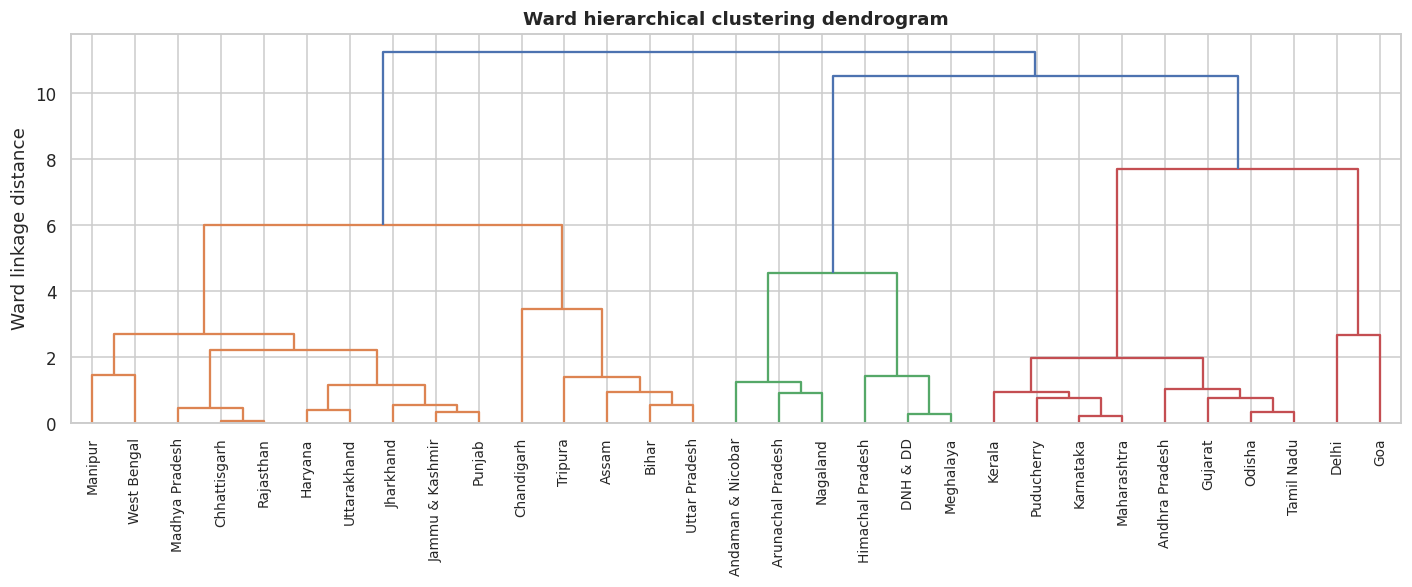

Adjusted Rand Index, K-Means vs Ward: 0.537


Hierarchical,0,1,2,3
K-Means,,,,
0,4,0,1,8
1,11,0,0,0
2,0,0,5,0
3,0,2,0,0


In [16]:
Z = linkage(Xp, method="ward")
fig, ax = plt.subplots(figsize=(13, 5.5))
dendrogram(Z, labels=df.index.tolist(), leaf_rotation=90, leaf_font_size=9, ax=ax)
ax.set(title="Ward hierarchical clustering dendrogram", ylabel="Ward linkage distance")
plt.tight_layout(); plt.show()

df["cluster_hc"] = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Xp)
ari = adjusted_rand_score(df.cluster, df.cluster_hc)
print(f"Adjusted Rand Index, K-Means vs Ward: {ari:.3f}")
display(pd.crosstab(df.cluster, df.cluster_hc,
                    rownames=["K-Means"], colnames=["Hierarchical"]))

## 11. Validation B - Stability Under Resampling

Two distinct questions, often conflated:

1. *Do a few extreme states drive the segmentation?* Delhi, Goa and Arunachal
   Pradesh sit beyond 3 SD on at least one feature.
2. *Would the segmentation survive a slightly different sample?* This is the
   honest test at n=31, and it is checked by **bootstrap resampling**: refit on
   90% subsamples many times and measure agreement with the full-sample labels
   using the Adjusted Rand Index.

Conventional reading of mean ARI: above 0.75 strong, 0.6-0.75 acceptable,
below 0.6 fragile.

Most extreme states (max |z| across features):
St
Delhi                4.28
Arunachal Pradesh    3.95
Goa                  3.17
Chandigarh           2.87
Bihar                2.78



Bootstrap stability over 200 resamples of 90% of states
  mean ARI   : 0.917
  median ARI : 1.000
  5th-95th   : 0.744 - 1.000


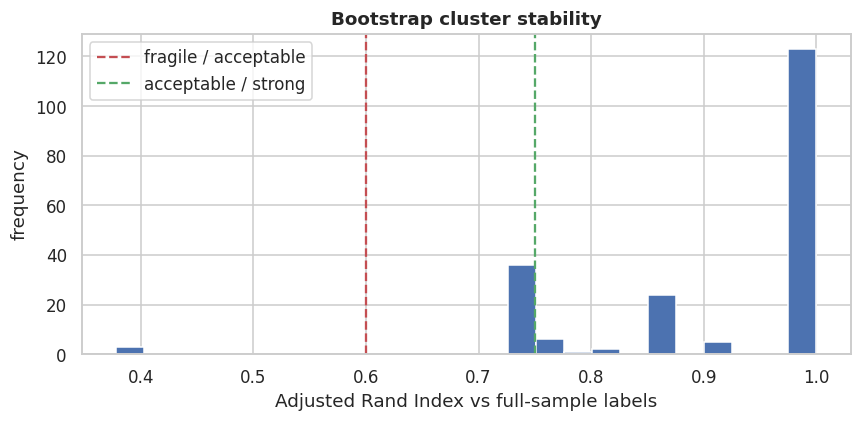

In [17]:
z = (df[FEATURES] - df[FEATURES].mean()) / df[FEATURES].std()
outliers = z.abs().max(axis=1).nlargest(5)
print("Most extreme states (max |z| across features):")
print(outliers.round(2).to_string())

rng = np.random.default_rng(RANDOM_STATE)
aris = []
for _ in range(200):
    idx = rng.choice(len(df), size=int(len(df) * .9), replace=False)
    Xb = StandardScaler().fit_transform(df.iloc[idx][FEATURES])
    Xpb = PCA(n_components=N_PC, random_state=RANDOM_STATE).fit_transform(Xb)
    lab = KMeans(n_clusters=K, n_init=25, random_state=RANDOM_STATE).fit_predict(Xpb)
    aris.append(adjusted_rand_score(df.iloc[idx].cluster, lab))
aris = np.array(aris)

print(f"\nBootstrap stability over 200 resamples of 90% of states")
print(f"  mean ARI   : {aris.mean():.3f}")
print(f"  median ARI : {np.median(aris):.3f}")
print(f"  5th-95th   : {np.percentile(aris,5):.3f} - {np.percentile(aris,95):.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(aris, bins=25, color="#4C72B0", edgecolor="w")
for v, c, l in [(.6, "#C44E52", "fragile / acceptable"), (.75, "#55A868", "acceptable / strong")]:
    ax.axvline(v, ls="--", c=c, lw=1.5, label=l)
ax.set(title="Bootstrap cluster stability", xlabel="Adjusted Rand Index vs full-sample labels",
       ylabel="frequency")
ax.legend(); plt.tight_layout(); plt.show()

In [18]:
# How often does each state keep its original segment across resamples?
counts = pd.Series(0, index=df.index, dtype=float)
appear = pd.Series(0, index=df.index, dtype=float)
for _ in range(200):
    idx = rng.choice(len(df), size=int(len(df) * .9), replace=False)
    sub = df.iloc[idx]
    Xb = StandardScaler().fit_transform(sub[FEATURES])
    Xpb = PCA(n_components=N_PC, random_state=RANDOM_STATE).fit_transform(Xb)
    lab = pd.Series(KMeans(n_clusters=K, n_init=25, random_state=RANDOM_STATE).fit_predict(Xpb),
                    index=sub.index)
    # map resample labels to original labels by majority overlap
    mapping = (pd.crosstab(lab, sub.cluster).idxmax(axis=1)).to_dict()
    agree = lab.map(mapping) == sub.cluster
    counts.loc[sub.index] += agree.astype(float)
    appear.loc[sub.index] += 1

stability = (counts / appear).sort_values()
print("Least stable states (share of resamples keeping their segment):")
print(stability.head(8).round(2).to_string())
print("\nStates stable in every resample:", int((stability == 1).sum()), "of", len(stability))

Least stable states (share of resamples keeping their segment):
St
West Bengal         0.61
Madhya Pradesh      0.71
Manipur             0.95
Chhattisgarh        0.96
Rajasthan           0.97
Himachal Pradesh    0.98
Jammu & Kashmir     0.99
Punjab              0.99

States stable in every resample: 19 of 31


## 12. Cluster Profiling and Naming

Clusters are named from their centroid profile, not from intuition about which
states "should" go together.

In [19]:
profile = (df.groupby("cluster")[FEATURES + ["ev_sales_2023", "pcs"]]
             .mean().round(2))
profile.insert(0, "n_states", df.cluster.value_counts().sort_index())
display(profile.style.background_gradient(cmap="RdYlGn", axis=0)
        .set_caption("Cluster centroid profile (feature means)"))

# Name clusters by demand intensity and infrastructure gap.
rank_gap    = profile.evs_per_station.rank(ascending=False)
rank_demand = profile.ev_per_lakh.rank(ascending=False)
score       = rank_demand + rank_gap
names = {}
for i, cl in enumerate(score.sort_values().index):
    names[cl] = ["Investment-Opportunity Markets", "Mature Markets",
                 "Emerging Markets", "Nascent Markets"][i]
df["segment"] = df.cluster.map(names)

for cl, nm in names.items():
    print(f"Cluster {cl} -> {nm:32s} : {', '.join(df[df.cluster==cl].index)}")

,n_states,ev_per_lakh,pcs_per_lakh,evs_per_station,log_market_size,cagr_19_23,share_2wheelers,share_3wheelers,share_4wheelers,ev_sales_2023,pcs
cluster,,,,,,,,,,,
0,13,129.740000,1.130000,133.160000,10.550000,1.270000,0.780000,0.140000,0.070000,69120.230000,651.690000
1,11,156.850000,0.590000,329.540000,9.800000,0.770000,0.220000,0.740000,0.040000,49381.550000,148.360000
2,5,7.940000,0.520000,35.480000,3.630000,0.630000,0.470000,0.050000,0.470000,65.200000,8.000000
3,2,542.480000,9.490000,61.250000,10.180000,1.610000,0.700000,0.180000,0.110000,41463.500000,999.500000


Cluster 1 -> Investment-Opportunity Markets   : Assam, Bihar, Chandigarh, Haryana, Jammu & Kashmir, Jharkhand, Manipur, Punjab, Tripura, Uttar Pradesh, Uttarakhand
Cluster 3 -> Mature Markets                   : Delhi, Goa
Cluster 0 -> Emerging Markets                 : Andhra Pradesh, Chhattisgarh, Gujarat, Himachal Pradesh, Karnataka, Kerala, Madhya Pradesh, Maharashtra, Odisha, Puducherry, Rajasthan, Tamil Nadu, West Bengal
Cluster 2 -> Nascent Markets                  : Andaman & Nicobar, Arunachal Pradesh, DNH & DD, Meghalaya, Nagaland


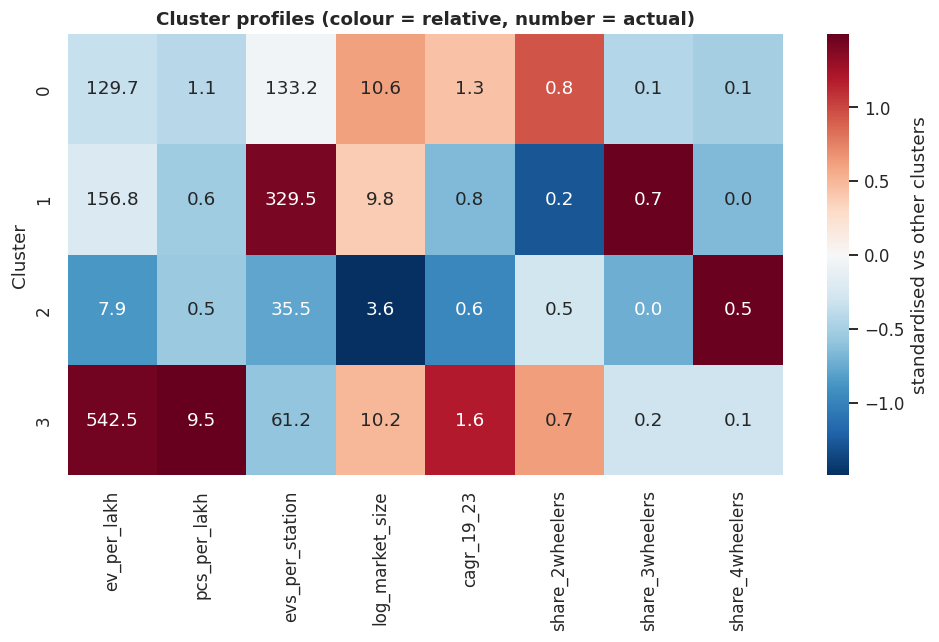

In [20]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(profile[FEATURES].apply(lambda s: (s - s.mean()) / s.std()),
            annot=profile[FEATURES].round(1), fmt="", cmap="RdBu_r", center=0,
            cbar_kws={"label": "standardised vs other clusters"}, ax=ax)
ax.set(title="Cluster profiles (colour = relative, number = actual)", ylabel="Cluster")
plt.tight_layout(); plt.show()

## 13. EV Investment Priority Score (EVIPS)

An arbitrary weighted index is the weakest point of any scoring exercise. Here the
weights are **derived from the PCA**, not chosen by hand: each component's absolute
loading is weighted by how much variance that component explains, so features that
drive real variation across states count for more.

Business direction is applied separately from magnitude:

| Component | Direction | Reasoning |
|---|---|---|
| `evs_per_station` | **+** | unmet demand is the opportunity |
| `cagr_19_23` | **+** | momentum sustains future utilisation |
| `log_market_size` | **+** | absolute volume supports payback |
| `pcs_per_lakh` | **-** | already-served markets offer less headroom |

In [21]:
SCORE_FEATURES = {"evs_per_station": +1, "cagr_19_23": +1,
                  "log_market_size": +1, "pcs_per_lakh": -1}

raw_w = (loadings.abs() * evr[:N_PC]).sum(axis=1)          # variance-weighted importance
w = raw_w[list(SCORE_FEATURES)] / raw_w[list(SCORE_FEATURES)].sum()
print("PCA-derived weights:"); print(w.round(3).to_string())

norm = pd.DataFrame(MinMaxScaler().fit_transform(df[list(SCORE_FEATURES)]),
                    index=df.index, columns=list(SCORE_FEATURES))
for f, sign in SCORE_FEATURES.items():
    if sign < 0:
        norm[f] = 1 - norm[f]

df["EVIPS"] = (norm * w).sum(axis=1) * 100

ranked = df.sort_values("EVIPS", ascending=False)
ranked["tier"] = pd.qcut(ranked.EVIPS.rank(ascending=False), 4,
                         labels=["Tier 1", "Tier 2", "Tier 3", "Tier 4"])

display(ranked[["segment", "ev_sales_2023", "pcs", "evs_per_station",
                "cagr_19_23", "EVIPS", "tier"]].round(2).head(15)
        .style.background_gradient(subset=["EVIPS"], cmap="RdYlGn")
        .set_caption("Top 15 states by EV Investment Priority Score"))

PCA-derived weights:
evs_per_station    0.211
cagr_19_23         0.224
log_market_size    0.292
pcs_per_lakh       0.273


,segment,ev_sales_2023,pcs,evs_per_station,cagr_19_23,EVIPS,tier
St,,,,,,,
Bihar,Investment-Opportunity Markets,88186.000000,124,711.180000,0.630000,81.120000,Tier 1
Assam,Investment-Opportunity Markets,60798.000000,86,706.950000,0.540000,78.920000,Tier 1
Uttar Pradesh,Investment-Opportunity Markets,277300.000000,582,476.460000,0.490000,75.910000,Tier 1
Gujarat,Emerging Markets,88617.000000,476,186.170000,2.110000,74.160000,Tier 1
Jammu & Kashmir,Investment-Opportunity Markets,9748.000000,47,207.400000,2.370000,71.480000,Tier 1
Odisha,Emerging Markets,44552.000000,198,225.010000,1.490000,69.870000,Tier 1
Kerala,Emerging Markets,74714.000000,852,87.690000,2.550000,69.470000,Tier 1
Chandigarh,Investment-Opportunity Markets,6333.000000,12,527.750000,0.880000,67.620000,Tier 1
Madhya Pradesh,Emerging Markets,67051.000000,341,196.630000,1.070000,67.220000,Tier 2


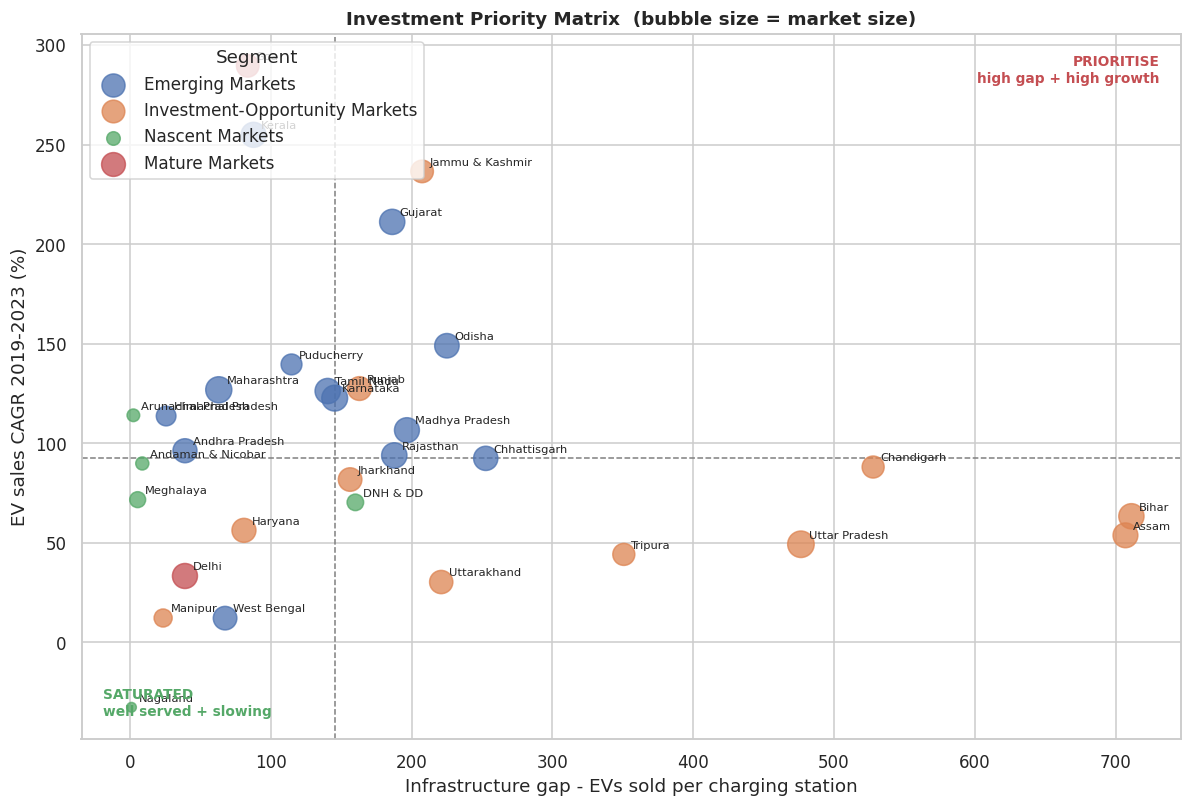


Tier -> recommended action
  Tier 1: Immediate expansion      Bihar, Assam, Uttar Pradesh, Gujarat, Jammu & Kashmir, Odisha, Kerala, Chandigarh
  Tier 2: Selective investment     Madhya Pradesh, Tamil Nadu, Rajasthan, Chhattisgarh, Karnataka, Punjab, Maharashtra, Jharkhand
  Tier 3: Pilot projects           Tripura, Andhra Pradesh, Uttarakhand, Haryana, Puducherry, West Bengal, Goa
  Tier 4: Monitor only             Himachal Pradesh, DNH & DD, Manipur, Meghalaya, Arunachal Pradesh, Andaman & Nicobar, Delhi, Nagaland


In [22]:
ACTIONS = {"Tier 1": "Immediate expansion",
           "Tier 2": "Selective investment",
           "Tier 3": "Pilot projects",
           "Tier 4": "Monitor only"}

fig, ax = plt.subplots(figsize=(11, 7.5))
sizes = 40 + 260 * MinMaxScaler().fit_transform(df[["log_market_size"]]).ravel()
for cl in sorted(df.cluster.unique()):
    m = df.cluster == cl
    ax.scatter(df.loc[m, "evs_per_station"], df.loc[m, "cagr_19_23"] * 100,
               s=sizes[m.values], alpha=.75, label=names[cl], zorder=3)
for st, r in df.iterrows():
    ax.annotate(st, (r.evs_per_station, r.cagr_19_23 * 100), fontsize=7.5,
                xytext=(5, 4), textcoords="offset points")

xm, ym = df.evs_per_station.median(), df.cagr_19_23.median() * 100
ax.axvline(xm, ls="--", c="grey", lw=1); ax.axhline(ym, ls="--", c="grey", lw=1)
ax.text(.98, .97, "PRIORITISE\nhigh gap + high growth", transform=ax.transAxes,
        ha="right", va="top", fontsize=9, weight="bold", color="#C44E52")
ax.text(.02, .03, "SATURATED\nwell served + slowing", transform=ax.transAxes,
        ha="left", va="bottom", fontsize=9, weight="bold", color="#55A868")
ax.set(title="Investment Priority Matrix  (bubble size = market size)",
       xlabel="Infrastructure gap - EVs sold per charging station",
       ylabel="EV sales CAGR 2019-2023 (%)")
ax.legend(title="Segment", loc="upper left")
plt.tight_layout(); plt.show()

print("\nTier -> recommended action")
for t, a in ACTIONS.items():
    states = ranked[ranked.tier == t].index.tolist()
    print(f"  {t}: {a:24s} {', '.join(states)}")

## 14. Export

Outputs feeding the written report and the presentation deck.

In [23]:
out = ranked[["segment", "tier", "EVIPS", "ev_sales_2023", "pcs", "population",
              "ev_per_lakh", "pcs_per_lakh", "evs_per_station", "cagr_19_23",
              "share_2wheelers", "share_3wheelers", "share_4wheelers", "cluster"]]
out.to_csv("ev_state_segmentation_results.csv")
profile.to_csv("cluster_profiles.csv")
diag.to_csv("k_selection_diagnostics.csv")
loadings.to_csv("pca_loadings.csv")
print("Exported 4 files.")
out.head(10).round(2)

Exported 4 files.


,segment,tier,EVIPS,ev_sales_2023,pcs,population,ev_per_lakh,pcs_per_lakh,evs_per_station,cagr_19_23,share_2wheelers,share_3wheelers,share_4wheelers,cluster
St,,,,,,,,,,,,,,
Bihar,Investment-Opportunity Markets,Tier 1,81.12,88186.0,124,104099452,84.71,0.12,711.18,0.63,0.14,0.85,0.01,1
Assam,Investment-Opportunity Markets,Tier 1,78.92,60798.0,86,31205576,194.83,0.28,706.95,0.54,0.04,0.95,0.00,1
Uttar Pradesh,Investment-Opportunity Markets,Tier 1,75.91,277300.0,582,199812341,138.78,0.29,476.46,0.49,0.14,0.84,0.02,1
Gujarat,Emerging Markets,Tier 1,74.16,88617.0,476,60439692,146.62,0.79,186.17,2.11,0.89,0.03,0.07,0
Jammu & Kashmir,Investment-Opportunity Markets,Tier 1,71.48,9748.0,47,12541302,77.73,0.37,207.40,2.37,0.19,0.78,0.01,1
Odisha,Emerging Markets,Tier 1,69.87,44552.0,198,41974218,106.14,0.47,225.01,1.49,0.86,0.11,0.03,0
Kerala,Emerging Markets,Tier 1,69.47,74714.0,852,33406061,223.65,2.55,87.69,2.55,0.82,0.05,0.12,0
Chandigarh,Investment-Opportunity Markets,Tier 1,67.62,6333.0,12,1055450,600.03,1.14,527.75,0.88,0.34,0.51,0.15,1
Madhya Pradesh,Emerging Markets,Tier 2,67.22,67051.0,341,72626809,92.32,0.47,196.63,1.07,0.54,0.44,0.02,0


## 15. Notes for the Report

**Challenges encountered (guidelines require at least three):**

1. **No common merge key.** Three sources, three geographic vintages, five
   irreconcilable state names. Resolved by fixing Census 2011 boundaries as
   canonical and folding Telangana and Ladakh into their parent states.
2. **Incomplete latest period.** The sales file's 2024 covers January only;
   using it would have understated current volumes by roughly 90%.
3. **Small n and outlier leverage.** 31 states with 8 features, containing points
   more than 3 SD from the mean. Addressed with PCA before clustering plus an
   explicit leave-outliers-out sensitivity test.

**Limitations to state:**

- Charging data is a single snapshot (02.02.2024); sales are calendar 2023. The
  slight mismatch means the gap metric is indicative, not exact.
- Telangana cannot be assessed independently because Vahan does not publish it.
- Mizoram, Lakshadweep and Sikkim are excluded for missing or zero data.
- Census 2011 population is 13+ years old; states have grown at different rates,
  so per-capita features carry some drift.
- State-level aggregation conceals intra-state variation - the real siting
  decision is made at city and highway-corridor level.